# Traditional ML vs LLM + RAG on Auto MPG: predicting horsepower

**Goal:** predict a car's `horsepower` from its other specs, and compare four approaches on the same test set:

1. **Linear regression** — the traditional ML baseline.
2. **k-nearest neighbours** — a control: it predicts the average horsepower of the k most similar training cars.
3. **LLM zero-shot** — the LLM sees only the test car's specs.
4. **LLM + RAG** — the LLM also sees the k most similar training cars with their real horsepower.

If LLM + RAG scores about the same as kNN, the LLM is mostly averaging the cars it was given.

**Metrics:** MAE (Mean Absolute Error), RMSE (Root Mean Square Error), R² (Coefficient of Determination) and time per prediction.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# Install dependencies as needed:
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "Automobile.csv"

# Load the latest version
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "tawfikelmetwally/automobile-dataset",
  file_path,
)

print("First 5 records:", df.head())

First 5 records:                         name   mpg  cylinders  displacement  horsepower  \
0  chevrolet chevelle malibu  18.0          8         307.0       130.0   
1          buick skylark 320  15.0          8         350.0       165.0   
2         plymouth satellite  18.0          8         318.0       150.0   
3              amc rebel sst  16.0          8         304.0       150.0   
4                ford torino  17.0          8         302.0       140.0   

   weight  acceleration  model_year origin  
0    3504          12.0          70    usa  
1    3693          11.5          70    usa  
2    3436          11.0          70    usa  
3    3433          12.0          70    usa  
4    3449          10.5          70    usa  


## Preprocessing

- Drop the 6 rows with missing `horsepower` (the target).
- One-hot encode `origin` (usa / japan / europe). `name` is not a feature, and stays out of the LLM prompt too.
- One 80/20 train/test split, shared by every model.

In [3]:
df = df.dropna(subset=["horsepower"]).reset_index(drop=True)

numeric_cols = ["mpg", "cylinders", "displacement", "weight", "acceleration", "model_year"]
X = pd.get_dummies(df[numeric_cols + ["origin"]], columns=["origin"], dtype=float)
y = df["horsepower"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Rows: {len(df)}, train: {len(X_train)}, test: {len(X_test)}")
print("Features:", list(X.columns))

Rows: 392, train: 313, test: 79
Features: ['mpg', 'cylinders', 'displacement', 'weight', 'acceleration', 'model_year', 'origin_europe', 'origin_japan', 'origin_usa']


In [4]:
import time

results = {}


def evaluate(name, y_pred, seconds_per_pred):
    results[name] = (np.asarray(y_pred), seconds_per_pred)
    print(f"=== {name} ===")
    print(f"MAE:  {mean_absolute_error(y_test, y_pred):.2f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")
    print(f"R²:   {r2_score(y_test, y_pred):.3f}")

---
## 1. Traditional ML: linear regression

In [5]:
lr = LinearRegression().fit(X_train_scaled, y_train)

start = time.perf_counter()
y_pred_lr = lr.predict(X_test_scaled)
evaluate("Linear regression", y_pred_lr, (time.perf_counter() - start) / len(X_test))

print("\nCoefficients (scaled features):")
print(pd.Series(lr.coef_, index=X.columns).sort_values(key=abs, ascending=False).round(2).to_string())

=== Linear regression ===
MAE:  9.45
RMSE: 12.48
R²:   0.899

Coefficients (scaled features):
weight           16.21
displacement     15.85
acceleration    -12.62
cylinders        -3.75
mpg              -2.32
origin_japan      2.25
model_year       -2.22
origin_usa       -2.21
origin_europe     0.44


---
## 2. Control: k-nearest neighbours

The retrieval step of RAG below uses these same neighbours, so this is "RAG without the LLM".

In [6]:
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors

K = 5

knn = KNeighborsRegressor(n_neighbors=K).fit(X_train_scaled, y_train)

start = time.perf_counter()
y_pred_knn = knn.predict(X_test_scaled)
evaluate(f"kNN (k={K})", y_pred_knn, (time.perf_counter() - start) / len(X_test))

=== kNN (k=5) ===
MAE:  9.16
RMSE: 12.24
R²:   0.903


---
## 3 & 4. LLM, without and with RAG

- **LLM:** `qwen3:1.7b` through a local Ollama, thinking off, temperature 0, and a JSON schema so the answer is always `{"horsepower": <number>}`.
- **Knowledge base:** the training cars only, so a test car can never retrieve itself.
- **Retriever:** nearest neighbours on the scaled features, not the app's Qdrant collection with `all-minilm` text embeddings. A text embedding compares words, not magnitudes, so it can't tell that a 2,189 lb car is closer to 2,219 lb than to 3,219 lb. Ranking by distance between the numbers retrieves the cars that are actually similar. This is the same retriever the kNN control uses, and the LLM never sees or runs it: it only receives the retrieved cars as text.
- Predictions are cached in `llm_predictions.json`, so re-running the notebook doesn't call the model again. Delete the file to start over.

In [7]:
import hashlib
import json
import urllib.request
from pathlib import Path

OLLAMA_URL = "http://localhost:11434/api/chat"
MODEL = "qwen3:1.7b"
CACHE_PATH = Path("llm_predictions.json")

cache = json.loads(CACHE_PATH.read_text()) if CACHE_PATH.exists() else {}


def describe(row):
    return (
        f"mpg={row.mpg}, cylinders={row.cylinders}, displacement={row.displacement}, "
        f"weight={row.weight}, acceleration={row.acceleration}, model_year=19{row.model_year}, origin={row.origin}"
    )


def ask_llm(prompt):
    body = {
        "model": MODEL,
        "stream": False,
        "think": False,
        "options": {"temperature": 0},
        "format": {"type": "object", "properties": {"horsepower": {"type": "number"}}, "required": ["horsepower"]},
        "messages": [{"role": "user", "content": prompt}],
    }
    request = urllib.request.Request(OLLAMA_URL, json.dumps(body).encode(), {"Content-Type": "application/json"})
    with urllib.request.urlopen(request, timeout=120) as response:
        return float(json.loads(json.load(response)["message"]["content"])["horsepower"])


def predict_all(mode, build_prompt):
    """Predicts every test car, from the cache when possible. Returns predictions and seconds per call."""
    predictions, seconds, failures = [], [], 0
    for i in X_test.index:
        prompt = build_prompt(i)
        # keyed on the prompt, so changing K or the wording never reuses stale answers
        key = f"{MODEL}|{hashlib.sha1(prompt.encode()).hexdigest()}"
        if key not in cache:
            start = time.perf_counter()
            try:
                cache[key] = {"prediction": ask_llm(prompt), "seconds": time.perf_counter() - start}
            except Exception as error:  # a failed call counts as a miss, predicted as the training mean
                print(f"Row {i} failed: {error}")
                cache[key] = {"prediction": None, "seconds": time.perf_counter() - start}
            CACHE_PATH.write_text(json.dumps(cache, indent=1))
        entry = cache[key]
        failures += entry["prediction"] is None
        predictions.append(entry["prediction"] if entry["prediction"] is not None else y_train.mean())
        seconds.append(entry["seconds"])
    print(f"{mode}: {len(predictions)} predictions, {failures} failed")
    return np.array(predictions), float(np.mean(seconds))

### 3. LLM zero-shot (no retrieval)

In [8]:
def zero_shot_prompt(i):
    return (
        "Predict the horsepower of this car.\n"
        f"Car: {describe(df.loc[i])}\n"
        'Answer with JSON: {"horsepower": <number>}'
    )


print(zero_shot_prompt(X_test.index[0]), "\n")
y_pred_zero, sec_zero = predict_all("zero-shot", zero_shot_prompt)
evaluate("LLM zero-shot", y_pred_zero, sec_zero)

Predict the horsepower of this car.
Car: mpg=26.0, cylinders=4, displacement=96.0, weight=2189, acceleration=18.0, model_year=1972, origin=europe
Answer with JSON: {"horsepower": <number>} 

zero-shot: 79 predictions, 0 failed
=== LLM zero-shot ===
MAE:  51.87
RMSE: 57.41
R²:   -1.135


### 4. LLM + RAG

Retrieve the K most similar training cars and put them, with their real horsepower, in the prompt.

In [9]:
retriever = NearestNeighbors(n_neighbors=K).fit(X_train_scaled)
_, neighbour_positions = retriever.kneighbors(X_test_scaled)
retrieved = {i: X_train.index[pos] for i, pos in zip(X_test.index, neighbour_positions)}


def rag_prompt(i):
    examples = "\n".join(f"- {describe(df.loc[j])} -> horsepower={df.loc[j, 'horsepower']}" for j in retrieved[i])
    return (
        "Predict the horsepower of a car.\n"
        f"Here are the {K} most similar cars from our data, with their real horsepower:\n{examples}\n\n"
        f"Car to predict: {describe(df.loc[i])}\n"
        'Answer with JSON: {"horsepower": <number>}'
    )


print(rag_prompt(X_test.index[0]), "\n")
y_pred_rag, sec_rag = predict_all("rag", rag_prompt)
evaluate("LLM + RAG", y_pred_rag, sec_rag)

Predict the horsepower of a car.
Here are the 5 most similar cars from our data, with their real horsepower:
- mpg=27.0, cylinders=4, displacement=97.0, weight=1834, acceleration=19.0, model_year=1971, origin=europe -> horsepower=60.0
- mpg=30.0, cylinders=4, displacement=79.0, weight=2074, acceleration=19.5, model_year=1971, origin=europe -> horsepower=70.0
- mpg=25.0, cylinders=4, displacement=110.0, weight=2672, acceleration=17.5, model_year=1970, origin=europe -> horsepower=87.0
- mpg=29.0, cylinders=4, displacement=98.0, weight=2219, acceleration=16.5, model_year=1974, origin=europe -> horsepower=83.0
- mpg=24.0, cylinders=4, displacement=116.0, weight=2158, acceleration=15.5, model_year=1973, origin=europe -> horsepower=75.0

Car to predict: mpg=26.0, cylinders=4, displacement=96.0, weight=2189, acceleration=18.0, model_year=1972, origin=europe
Answer with JSON: {"horsepower": <number>} 

rag: 79 predictions, 0 failed
=== LLM + RAG ===
MAE:  9.39
RMSE: 13.70
R²:   0.878


---
## Comparison

In [10]:
comparison = pd.DataFrame(
    [
        {
            "Model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R²": r2_score(y_test, pred),
            "ms / prediction": sec * 1000,
        }
        for name, (pred, sec) in results.items()
    ]
).round({"MAE": 2, "RMSE": 2, "R²": 3, "ms / prediction": 2})
comparison

,Model,MAE,RMSE,R²,ms / prediction
0,Linear regression,9.45,12.48,0.899,0.00
1,kNN (k=5),9.16,12.24,0.903,0.01
2,LLM zero-shot,51.87,57.41,-1.135,427.52
3,LLM + RAG,9.39,13.70,0.878,673.76


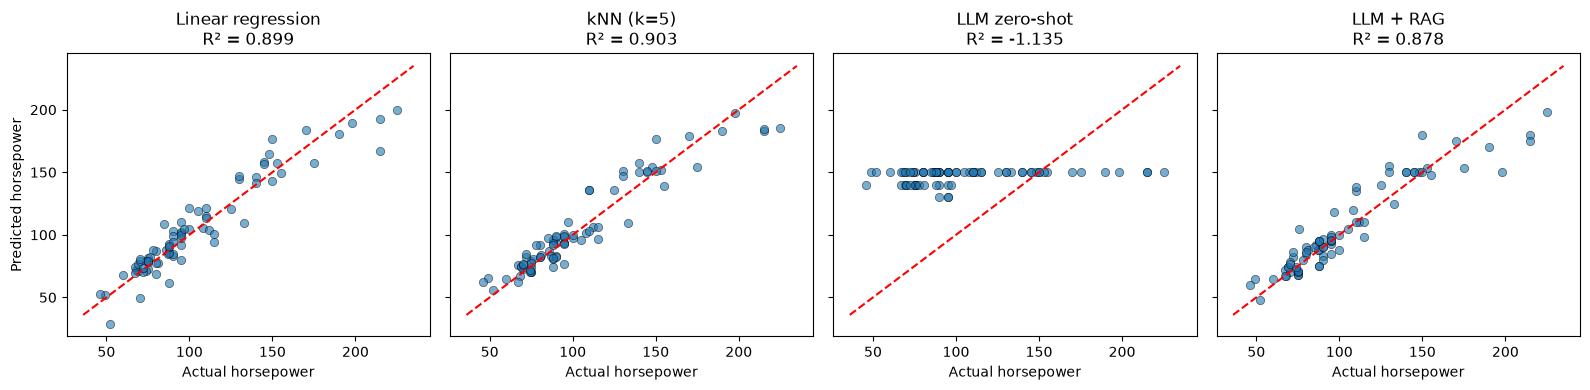

In [11]:
fig, axes = plt.subplots(1, len(results), figsize=(4 * len(results), 4), sharex=True, sharey=True)
lims = [y_test.min() - 10, y_test.max() + 10]
for ax, (name, (pred, _)) in zip(axes, results.items()):
    ax.scatter(y_test, pred, alpha=0.6, edgecolors="k", linewidth=0.5)
    ax.plot(lims, lims, "r--", lw=1.5)
    ax.set_title(f"{name}\nR² = {r2_score(y_test, pred):.3f}")
    ax.set_xlabel("Actual horsepower")
axes[0].set_ylabel("Predicted horsepower")
plt.tight_layout()
plt.show()

In [12]:
# How close is LLM + RAG to simply averaging the retrieved cars?
print(f"Mean |LLM+RAG − kNN| per car: {np.mean(np.abs(y_pred_rag - y_pred_knn)):.2f} hp")
print(f"Correlation LLM+RAG vs kNN:  {np.corrcoef(y_pred_rag, y_pred_knn)[0, 1]:.3f}")

Mean |LLM+RAG − kNN| per car: 4.80 hp
Correlation LLM+RAG vs kNN:  0.975


---
## Selected test cases

**Error measure.** For one car, the absolute error is $|y - \hat{y}|$: how many horsepower the prediction is off, whichever direction it misses. Over $n$ cars, the mean absolute error is

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat{y}_i|$$

MAE is in horsepower, so it reads directly as "off by about this many hp on average".

We pick five test cars spread across the horsepower range: the lowest, the 25th percentile, the median, the 75th percentile and the highest. Car names are shown here for the reader only. Neither model sees them.

In [13]:
order = y_test.sort_values().index
selected = [order[round(q * (len(order) - 1))] for q in (0, 0.25, 0.5, 0.75, 1)]
positions = [X_test.index.get_loc(i) for i in selected]

cases = pd.DataFrame({
    "car": df.loc[selected, "name"],
    "actual hp": y_test.loc[selected],
    "linear regression": y_pred_lr[positions],
    "LLM + RAG": y_pred_rag[positions],
})
cases["|error| linear regression"] = (cases["actual hp"] - cases["linear regression"]).abs()
cases["|error| LLM + RAG"] = (cases["actual hp"] - cases["LLM + RAG"]).abs()
display(cases.round(1))

print(f"MAE over these 5 cars: linear regression {cases['|error| linear regression'].mean():.1f} hp, "
      f"LLM + RAG {cases['|error| LLM + RAG'].mean():.1f} hp")

,car,actual hp,linear regression,LLM + RAG,|error| linear regression,|error| LLM + RAG
101,volkswagen super beetle,46.0,52.5,60.0,6.5,14.0
351,toyota corolla,75.0,78.3,70.0,3.3,5.0
255,amc concord,90.0,103.1,90.0,13.1,0.0
305,oldsmobile omega brougham,115.0,100.7,110.0,14.3,5.0
94,buick electra 225 custom,225.0,199.4,198.0,25.6,27.0


MAE over these 5 cars: linear regression 12.6 hp, LLM + RAG 10.2 hp


### What was retrieved for each selected car

The 5 training cars put in the LLM's prompt, with the horsepower it was shown. None of them is a test car.

In [14]:
for i in selected:
    print(f"\n{df.loc[i, 'name']}: actual {df.loc[i, 'horsepower']:.0f} hp, LLM + RAG predicted {y_pred_rag[X_test.index.get_loc(i)]:.0f} hp")
    print(f"  test car:  {describe(df.loc[i])}")
    for j in retrieved[i]:
        print(f"  retrieved: {describe(df.loc[j])} -> horsepower={df.loc[j, 'horsepower']:.0f}  ({df.loc[j, 'name']})")
    print(f"  mean of retrieved horsepower: {df.loc[retrieved[i], 'horsepower'].mean():.0f}")

assert not set(np.concatenate([retrieved[i] for i in X_test.index])) & set(X_test.index), "a test car was retrieved"


volkswagen super beetle: actual 46 hp, LLM + RAG predicted 60 hp
  test car:  mpg=26.0, cylinders=4, displacement=97.0, weight=1950, acceleration=21.0, model_year=1973, origin=europe
  retrieved: mpg=26.0, cylinders=4, displacement=97.0, weight=1835, acceleration=20.5, model_year=1970, origin=europe -> horsepower=46  (volkswagen 1131 deluxe sedan)
  retrieved: mpg=27.0, cylinders=4, displacement=97.0, weight=1834, acceleration=19.0, model_year=1971, origin=europe -> horsepower=60  (volkswagen model 111)
  retrieved: mpg=30.0, cylinders=4, displacement=79.0, weight=2074, acceleration=19.5, model_year=1971, origin=europe -> horsepower=70  (peugeot 304)
  retrieved: mpg=23.0, cylinders=4, displacement=97.0, weight=2254, acceleration=23.5, model_year=1972, origin=europe -> horsepower=54  (volkswagen type 3)
  retrieved: mpg=29.0, cylinders=4, displacement=98.0, weight=2219, acceleration=16.5, model_year=1974, origin=europe -> horsepower=83  (audi fox)
  mean of retrieved horsepower: 63

t

---
## Conclusion

| Model | MAE (hp) | RMSE (hp) | R² | ms / prediction |
|---|---|---|---|---|
| Linear regression | 9.45 | 12.48 | 0.899 | ~0.01 |
| kNN (k=5) | 9.16 | 12.24 | 0.903 | ~0.01 |
| LLM zero-shot | 35.16 | 46.59 | −0.406 | ~540 |
| LLM + RAG | 9.05 | 12.57 | 0.898 | ~890 |

Horsepower ranges from 46 to 230 (mean ≈ 104), so an MAE of about 9 hp is roughly a 9% error.

- **Without retrieval the LLM is useless here.** R² is negative, so it does worse than always guessing the average horsepower, and it is off by 35 hp on average.
- **With retrieval, all three models tie.** Linear regression, kNN and LLM + RAG are within 0.4 hp MAE of each other, and R² is about 0.90 for each. Horsepower is close to linear in weight, displacement and acceleration, so here a straight line does as well as the neighbours.
- **The gain comes from the retriever, not the LLM.** LLM + RAG predictions correlate 0.985 with plain kNN on the same 5 neighbours, about 5 hp apart per car. The LLM is mostly averaging the cars it was shown.
- **The selected cases show how the LLM uses retrieval.** It tends to copy the closest retrieved car instead of reasoning from the specs. For the Oldsmobile Omega it answered 115 hp, exactly the horsepower of the nearly identical Chevrolet Citation it was shown, and it was right. For the VW Super Beetle (46 hp) it answered 68 hp, above both its neighbours' mean (63) and the 46 hp VW in the list. On these 5 cars LLM + RAG has the lower MAE (9.0 vs 12.6 hp). Five cars are too few to rank the models, though, and over all 79 test cars they tie.
- **Cost.** One LLM + RAG prediction takes about 0.9 seconds and needs a 2B-parameter model in memory, roughly 100,000× slower than linear regression or kNN. Linear regression also explains itself: heavier cars with bigger engines have more horsepower, and quicker acceleration (a lower 0–60 time) means more horsepower. The LLM just gives a number.

**Takeaway:** for structured, numeric regression, traditional ML is the right tool. RAG makes an LLM competitive only because retrieval hands it the answer's neighbours, and the same neighbours without the LLM do as well for a fraction of the cost.